# Hiérarchie de concepts grammaticaux (EWT)

**Question.** Quand on retire l'encodage le plus direct d'un concept spécifique, les supports suivants de la boucle s'appuient-ils sur un concept **plus général** qui le contient ? Par exemple, pour « verbe au passif » : S₁ contiendrait des neurones propres au passif, et les niveaux suivants des neurones qui codent « verbe » en général.

**Données.** Le corpus Universal Dependencies English Web Treebank (EWT), annoté à la main au niveau du mot (catégorie grammaticale, temps, nombre, voix, …). Gurnee et al. l'utilisent pour leurs features linguistiques ; leur figure 5c montre justement un neurone « verbe passif » à fort rappel et un neurone « verbe » à forte précision, mais sans analyse de hiérarchie.

**Représentation.** Pour chaque mot, l'activation des 2 048 neurones MLP (post-GELU) d'une couche de Pythia-70m, prise au **dernier token** du mot (le moment où le modèle a lu le mot entier). Gurnee et al. étiquettent tous les tokens d'un mot ; on garde un seul token par mot pour éviter de compter un mot plusieurs fois.

**Paires parent → enfant testées.**

| Enfant | Parent |
|---|---|
| verbe au passif (`Voice=Pass`) | verbe (`VERB`) |
| verbe au passé, forme finie (`Tense=Past`, `VerbForm=Fin`) | verbe |
| gérondif (`VerbForm=Ger`) | verbe |
| nom pluriel (`Number=Plur`) | nom (`NOUN`) |
| pronom personnel (`PronType=Prs`) | pronom (`PRON`) |

**Deux façons de définir les négatifs** pour chaque enfant :
- **global** : l'enfant contre tous les autres mots. Les neurones du parent aident à prédire l'enfant (un verbe passif est d'abord un verbe). C'est là qu'on cherche la hiérarchie.
- **within** : l'enfant contre les autres membres du parent (passif contre autres verbes), comme Gurnee et al. pour la voix. Les neurones du parent n'aident plus : c'est le contrôle.

On lance aussi la boucle sur les parents eux-mêmes (`is_verb`, `is_noun`, `is_pron`) pour comparer leurs supports à ceux des enfants.

**Prérequis.** `build_ewt_dataset.py` puis `extract_ewt_activations.py` (voir le README).

In [24]:
import os, sys, time, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression as SkLogReg
from sklearn.metrics import f1_score, roc_auc_score, log_loss, precision_score, recall_score

sys.path.insert(0, os.path.abspath("../.."))
from picpy.calibration import BinomialCalibrator
from picpy import LogisticRegression
from picpy.penalties import SCADPenalty
from picpy.selection import RecursiveSelection

os.environ["PYTHONWARNINGS"] = "ignore"
warnings.simplefilter("ignore")

MODEL = "pythia-70m"
ACT_DIR = f"cached_activations/{MODEL}/ewt"          # tous les mots d'EWT
LAYERS = [0, 1, 2, 3, 4, 5]
TASKS_RUN = [
    # lexicales
    "det_def_vs_indef", "pron_nom_vs_acc", "is_verb",
    # intermédiaires
    "passive_vs_active_participle", "past_vs_participle", "noun_vs_verb_ambig",
    # contextuelles
    "aux_vs_verb_have_do", "subj_vs_obj_noun", "to_part_vs_adp",
]

# comparaison à taille égale : même nombre de positifs et de négatifs pour toutes les tâches
N_PER_CLASS = None       # None = fixé par la tâche la plus rare (aux_vs_verb_have_do : 1 882)
SEEDS = [0, 1, 2]        # tirages répétés du sous-échantillon
TEST_FRAC = 0.3

# boucle PIC
MAX_ITER = 100
ALPHA, N_SIMU = 0.05, 2000
K_SWEEP = [1, 2, 4, 8, 16, 32]                       # baseline de Gurnee et al.
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
N_JOBS = 4                                           # boucles simultanées sur le GPU

OUT_BASE = f"results/{MODEL}/ewt_full_n1882"  # nouveau dossier : ne pas mélanger avec le run à 946


def result_path(name, l, seed):
    d = f"{OUT_BASE}/seed{seed}"
    os.makedirs(d, exist_ok=True)
    return f"{d}/{name.replace('|', '__')}_L{l}.pkl"


W = pd.read_csv(f"{ACT_DIR}/words.csv", keep_default_na=False)
_cache = {}


def load_layer(l):
    """Activations (n_mots x 2048) en float16, lues sur le disque à la demande."""
    if l not in _cache:
        _cache[l] = np.load(f"{ACT_DIR}/{l}.npy", mmap_mode="r")
    return _cache[l]


def cohen_d(X, y):
    y = np.asarray(y, bool)
    m1, m0 = X[y].mean(0), X[~y].mean(0)
    return (m1 - m0) / np.sqrt(0.5 * (X[y].var(0) + X[~y].var(0)) + 1e-8)


print(f"{len(W)} mots, device = {DEVICE}, {len(TASKS_RUN)} tâches x {len(LAYERS)} couches x {len(SEEDS)} tirages")

240302 mots, device = cuda, 9 tâches x 6 couches x 3 tirages


## Définition des tâches

Chaque tâche est un problème binaire : `pos` (le concept) contre `neg`. Le tableau donne le nombre de positifs et de négatifs. Les enfants rares (le passif représente environ 1 % des mots) ont peu de positifs : vérifier qu'il y en a au moins quelques centaines avant d'interpréter.

**Tâche contextuelle `past_vs_participle`.** Toutes les tâches ci-dessus se devinent surtout à partir du mot seul (AUC de 0,90 à 1,00 en regardant seulement la forme du mot). On ajoute donc une tâche où le mot ne suffit pas : le **passé simple** (`Tense=Past`, `VerbForm=Fin`, « I *worked* ») contre le **participe passé** (`VerbForm=Part`, « I have *worked* », « it was *worked* »). La forme est souvent identique, et seul le contexte (la présence d'un auxiliaire) tranche : le mot seul ne donne qu'une AUC de 0,83. Si un ordre entre couches existe, c'est sur ce type de concept qu'il devrait apparaître, l'information de contexte étant rassemblée au fil des couches.

**Deuxième tâche contextuelle `passive_vs_active_participle`.** Parmi les participes passés, le **passif** (`Voice=Pass`, « it was *written* ») contre l'**actif** (« she has *written* »). Le mot est le même ; seul l'auxiliaire (*be* contre *have*) et la structure de la phrase tranchent. Le mot seul donne une AUC d'environ 0,85. Cette tâche sert à vérifier que le schéma observé sur `past_vs_participle` (contexte dans les couches intermédiaires, couche 0 au niveau du mot seul) se répète sur un autre concept contextuel.

In [25]:
up = W.upos.to_numpy()
form = W.form.str.lower().to_numpy()
lem = W.lemma.str.lower().to_numpy()
dep = W.deprel.str.split(":").str[0].to_numpy()
feat = lambda k, v: (W[k] == v).to_numpy()

verb, noun, pron = up == "VERB", up == "NOUN", up == "PRON"
part = verb & feat("VerbForm", "Part")
# formes vues au moins 3 fois comme NOUN et au moins 3 fois comme VERB ("work", "use", "need"...)
ct = pd.crosstab(form, up)
amb_nv = np.isin(form, ct.index[(ct.get("NOUN", 0) >= 3) & (ct.get("VERB", 0) >= 3)])

PAIRS = {   # nom : (positifs, négatifs)
    # lexicales : la forme décide presque seule
    "det_def_vs_indef":     ((up == "DET") & feat("Definite", "Def"), (up == "DET") & feat("Definite", "Ind")),
    "pron_nom_vs_acc":      (pron & feat("Case", "Nom"), pron & feat("Case", "Acc")),
    "is_verb":              (verb, ~verb),
    # intermédiaires : forme souvent ambiguë
    "passive_vs_active_participle": (part & feat("Voice", "Pass"), part & ~feat("Voice", "Pass")),
    "past_vs_participle":   (verb & feat("Tense", "Past") & feat("VerbForm", "Fin"), part),
    "noun_vs_verb_ambig":   (noun & amb_nv, verb & amb_nv),
    # contextuelles : même forme, rôle différent
    "aux_vs_verb_have_do":  ((up == "AUX") & np.isin(lem, ["have", "do"]), verb & np.isin(lem, ["have", "do"])),
    "subj_vs_obj_noun":     (noun & (dep == "nsubj"), noun & (dep == "obj")),
    "to_part_vs_adp":       ((form == "to") & (up == "PART"), (form == "to") & (up == "ADP")),
}
TASKS = {k: dict(pos=p, neg=n & ~p) for k, (p, n) in PAIRS.items()}
CHILDREN_RUN = []        # plus de hiérarchie : les cellules qui en dépendent sont sautées

if N_PER_CLASS is None:
    N_PER_CLASS = min(min(int(TASKS[k]["pos"].sum()), int(TASKS[k]["neg"].sum())) for k in TASKS_RUN)
print(f"{N_PER_CLASS} mots par classe ({int(2 * N_PER_CLASS * (1 - TEST_FRAC))} en entraînement)")


def task_split(name, seed):
    """N_PER_CLASS positifs et N_PER_CLASS négatifs tirés au hasard, puis découpage train/test."""
    t = TASKS[name]
    rng = np.random.default_rng(seed)
    idx = np.concatenate([rng.choice(np.where(t["pos"])[0], N_PER_CLASS, replace=False),
                          rng.choice(np.where(t["neg"])[0], N_PER_CLASS, replace=False)])
    y = t["pos"][idx].astype(int)
    return train_test_split(idx, y, test_size=TEST_FRAC, stratify=y, random_state=seed)


def lexical_auc(name, seed):
    """AUC d'un prédicteur qui ne voit que la forme du mot (taux de positifs par forme, appris sur le train),
    et part des mots test dont la forme apparaît avec les deux labels dans le train."""
    tr, te, ytr, yte = task_split(name, seed)
    s = pd.DataFrame({"f": form[tr], "y": ytr}).groupby("f").y.agg(["sum", "count"])
    prior = ytr.mean()
    p = pd.Series(form[te]).map((s["sum"] + prior) / (s["count"] + 1)).fillna(prior).to_numpy()
    both = s.index[(s["sum"] > 0) & (s["sum"] < s["count"])]
    return roc_auc_score(yte, p), np.isin(form[te], both).mean()


CTX = pd.DataFrame({k: dict(positifs=int(TASKS[k]["pos"].sum()), negatifs=int(TASKS[k]["neg"].sum()),
                            AUC_lexicale=np.mean([lexical_auc(k, s)[0] for s in SEEDS]),
                            part_formes_ambigues=np.mean([lexical_auc(k, s)[1] for s in SEEDS]))
                    for k in TASKS_RUN}).T.sort_values("AUC_lexicale", ascending=False)
os.makedirs(OUT_BASE, exist_ok=True)
CTX.to_csv(f"{OUT_BASE}/contextualite.csv")
display(CTX.round(3))

1882 mots par classe (2634 en entraînement)


,positifs,negatifs,AUC_lexicale,part_formes_ambigues
det_def_vs_indef,10686.0,5156.0,1.000,0.000
pron_nom_vs_acc,10041.0,3209.0,0.949,0.344
is_verb,26926.0,213376.0,0.920,0.076
passive_vs_active_participle,3192.0,3744.0,0.884,0.220
past_vs_participle,3957.0,6936.0,0.858,0.376
noun_vs_verb_ambig,4371.0,4751.0,0.838,0.876
aux_vs_verb_have_do,1882.0,2210.0,0.700,0.950
subj_vs_obj_noun,5384.0,8368.0,0.602,0.333
to_part_vs_adp,3899.0,2176.0,0.500,1.000


## Boucle de sélection et baseline de Gurnee et al.

Pour chaque tâche et chaque couche de `LAYERS` :
- **baseline k = 1** (Gurnee et al.) : les 10 neurones de plus grande différence de moyennes, puis une logistique sur un seul neurone ; on garde le meilleur F1 test ;
- **sparsity sweep** : les k premiers neurones par différence de moyennes, k ∈ `K_SWEEP` ;
- **boucle PIC** : les supports S₁, S₂, … ; chaque Sₜ est évalué seul sur le test (F1, précision, rappel, AUC, log-loss).

Les résultats sont enregistrés tâche par tâche dans `results/<model>/ewt/`. Si une tâche est déjà enregistrée, elle est sautée : on peut interrompre puis relancer la cellule. Pour tout recalculer, supprimer les fichiers `.pkl`.

In [26]:
def eval_support(S, Xtr, ytr, Xte, yte):
    S = np.atleast_1d(np.asarray(S, int))
    bal = SkLogReg(class_weight="balanced", max_iter=2000).fit(Xtr[:, S], ytr)
    pred = bal.predict(Xte[:, S])
    raw = SkLogReg(max_iter=2000).fit(Xtr[:, S], ytr)          # probabilités non repondérées
    p = np.clip(raw.predict_proba(Xte[:, S])[:, 1], 1e-7, 1 - 1e-7)
    return dict(f1=f1_score(yte, pred), precision=precision_score(yte, pred, zero_division=0),
                recall=recall_score(yte, pred), auc=roc_auc_score(yte, p), logloss=log_loss(yte, p))

In [19]:
from joblib import Parallel, delayed


def run_one(name, l, seed):
    import warnings, torch
    from threadpoolctl import threadpool_limits
    warnings.simplefilter("ignore")
    torch.set_num_threads(2)
    if os.path.exists(result_path(name, l, seed)):
        return None
    with threadpool_limits(2):
        X16 = np.load(f"{ACT_DIR}/{l}.npy", mmap_mode="r")
        tr, te, ytr, yte = task_split(name, seed)
        Xtr, Xte = X16[tr].astype(np.float32), X16[te].astype(np.float32)
        mu, sd = Xtr.mean(0), np.maximum(Xtr.std(0), 1e-3)
        Xtr, Xte = (Xtr - mu) / sd, (Xte - mu) / sd

        # baseline de Gurnee et al.
        d = Xtr[ytr == 1].mean(0) - Xtr[ytr == 0].mean(0)
        rank = np.argsort(-np.abs(d))
        k1 = [eval_support([j], Xtr, ytr, Xte, yte)["f1"] for j in rank[:10]]
        sweep = {k: eval_support(rank[:k], Xtr, ytr, Xte, yte) for k in K_SWEEP}

        # boucle PIC
        rec = RecursiveSelection(
            model=LogisticRegression(lambda_=0, penalty=SCADPenalty(), refit=False, dtype="float32"),
            calibrator=BinomialCalibrator(alpha=ALPHA, n_simu=N_SIMU),
            max_iter=MAX_ITER, progress=False,
        )
        Xfit = torch.tensor(Xtr, device=DEVICE, dtype=torch.float32) if DEVICE == "cuda" else Xtr
        t0 = time.time()
        rec.fit(Xfit, ytr.astype(float))
        supports = [np.asarray(S, int) for S in rec.supports_]
        levels = [eval_support(S, Xtr, ytr, Xte, yte) for S in supports]

        res = dict(task=name, layer=l, seed=seed, n_train=len(tr), n_test=len(te), pos_frac=float(ytr.mean()),
                   idx_tr=tr, idx_te=te, supports=supports, sizes=[len(S) for S in supports],
                   levels=levels, hit_max_iter=len(supports) >= MAX_ITER,
                   baseline_top10=rank[:10], baseline_k1_f1=float(np.max(k1)),
                   baseline_best=int(rank[int(np.argmax(k1))]), baseline_sweep=sweep,
                   lambdas=np.asarray(getattr(rec, "lambdas_", [])), fit_seconds=time.time() - t0)
        with open(result_path(name, l, seed), "wb") as f:
            pickle.dump(res, f)
    return (f"seed{seed} L{l} {name:<28} K={len(supports)}{' (limite)' if res['hit_max_iter'] else ''} "
            f"| {sum(res['sizes'])} neurones | {res['fit_seconds']:.0f} s "
            f"| AUC S1={levels[0]['auc'] if levels else float('nan'):.3f}")


jobs = [(name, l, s) for s in SEEDS for name in TASKS_RUN for l in LAYERS
        if not os.path.exists(result_path(name, l, s))]
print(f"{len(jobs)} boucles à lancer, {N_JOBS} en parallèle")
for msg in Parallel(n_jobs=N_JOBS, backend="loky", return_as="generator_unordered")(
        delayed(run_one)(name, l, s) for name, l, s in jobs):
    if msg:
        print(msg, flush=True)

RES = {}
for s in SEEDS:
    for l in LAYERS:
        for name in TASKS_RUN:
            p = result_path(name, l, s)
            if os.path.exists(p):
                with open(p, "rb") as f:
                    RES[(name, l, s)] = pickle.load(f)
print(f"{len(RES)} résultats chargés")

180 boucles à lancer, 4 en parallèle
seed0 L0 det_def_vs_indef             K=100 (limite) | 996 neurones | 400 s | AUC S1=1.000


KeyboardInterrupt: 

## Vue d'ensemble et comparaison à Gurnee et al.

Pour chaque tâche et chaque couche : la profondeur K (avec `+` si la boucle a atteint `MAX_ITER` sans s'arrêter), la taille de S₁, le F1 test de S₁ et du dernier support, et le F1 du meilleur neurone seul (baseline de Gurnee et al.).

La figure place chaque support Sₜ de la boucle (points) en regard de la courbe « F1 selon le nombre de neurones » de leur sparsity sweep (ligne). Un point au-dessus de la courbe signifie qu'un support de la boucle prédit mieux que les mêmes nombres de neurones choisis par différence de moyennes. Les points des niveaux élevés montrent ce qui reste prédictible une fois les meilleurs supports retirés.

F1_S1        F1_last        F1_meilleur_neurone         \
layer                    1      4       1      4                   1      4   
task                                                                          
is_verb              0.868  0.893   0.244  0.324               0.673  0.845   
verb_passive|global  0.735  0.650   0.081  0.091               0.828  0.495   
verb_past|global     0.724  0.758   0.140  0.119               0.713  0.560   
verb_past|within     0.753  0.822   0.285  0.274               0.534  0.623   

                      K      S1      
layer                 1   4   1   4  
task                                 
is_verb              19  40  45  29  
verb_passive|global  30  45  14  18  
verb_past|global     32  50  16   9  
verb_past|within     20  29  18  12

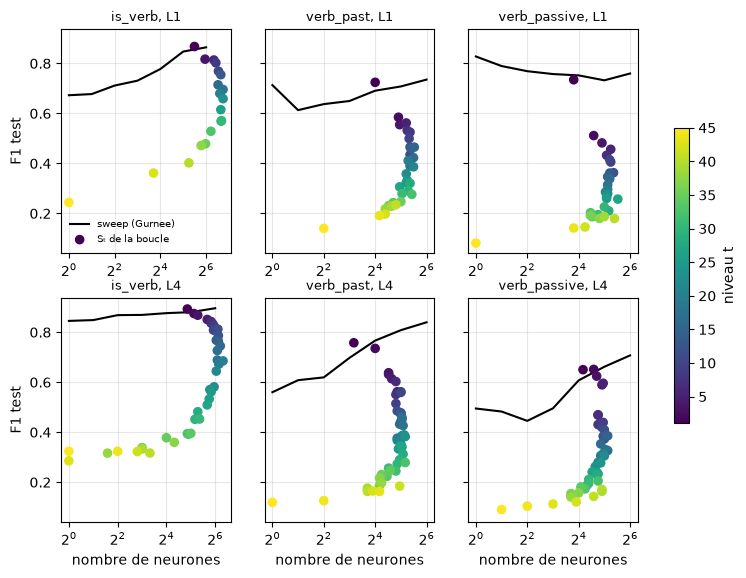

In [15]:
from matplotlib import cm, colors

# ---- une ligne par (tâche, couche, tirage) ----
rows = []
for (name, l, s), r in RES.items():
    rows.append(dict(task=name, layer=l, seed=s, K=len(r["supports"]), limite=r["hit_max_iter"],
                     neurones=int(sum(r["sizes"])), S1=r["sizes"][0] if r["sizes"] else 0,
                     AUC_S1=r["levels"][0]["auc"] if r["levels"] else np.nan,
                     AUC_last=r["levels"][-1]["auc"] if r["levels"] else np.nan,
                     AUC_top1=r["baseline_sweep"][1]["auc"]))
atlas = pd.DataFrame(rows)
atlas.to_csv(f"{OUT_BASE}/atlas.csv", index=False)
order = [t for t in CTX.index if t in set(atlas.task)]       # du plus lexical au plus contextuel

# ---- tableau : moyenne ± écart-type sur les tirages ----
g = atlas.groupby(["task", "layer"])
fmt = lambda m, s: f"{m:.0f} ± {s:.0f}" if np.isfinite(s) else f"{m:.0f}"
tab = pd.DataFrame({
    "K": g.K.agg(lambda x: fmt(x.mean(), x.std())),
    "neurones": g.neurones.agg(lambda x: fmt(x.mean(), x.std())),
    "AUC_S1": g.AUC_S1.mean().round(3),
    "AUC_top1": g.AUC_top1.mean().round(3),
    "limite": g.limite.any(),
}).reset_index()
display(tab.pivot(index="task", columns="layer", values="K").loc[order]
        .assign(AUC_lexicale=CTX.loc[order, "AUC_lexicale"].round(3)))
display(tab.pivot(index="task", columns="layer", values=["AUC_S1", "AUC_top1"]).loc[order])
if tab.limite.any():
    print("Limite MAX_ITER atteinte pour :", tab[tab.limite][["task", "layer"]].values.tolist())

# ---- figure 1 : K et neurones utilisés par couche, une ligne par tâche, couleur = contextualité ----
norm = colors.Normalize(vmin=CTX.loc[order, "AUC_lexicale"].min(), vmax=1.0)
cmap = cm.get_cmap("coolwarm_r")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name in order:
    d = atlas[atlas.task == name].groupby("layer")
    c = cmap(norm(CTX.loc[name, "AUC_lexicale"]))
    for ax, col in zip(axes, ["K", "neurones"]):
        m, s = d[col].mean(), d[col].std()
        ax.errorbar(m.index, m.values, yerr=s.values, color=c, marker="o", ms=4, capsize=2, label=name)
axes[0].set_ylabel("K (profondeur)")
axes[1].set_ylabel("neurones utilisés (sur 2 048)")
for ax in axes:
    ax.set_xlabel("couche"); ax.set_xticks(LAYERS); ax.grid(alpha=0.3)
fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes, label="AUC lexicale (rouge = contextuel)")
axes[1].legend(frameon=False, fontsize=7, bbox_to_anchor=(1.25, 1), loc="upper left")
plt.show()

# ---- figure 2 : boucle vs sparsity sweep (Gurnee), tirage 0 ----
fig, axes = plt.subplots(len(LAYERS), len(order), figsize=(2.6 * len(order), 2.6 * len(LAYERS)),
                         squeeze=False, sharey=True)
for i, l in enumerate(LAYERS):
    for j, name in enumerate(order):
        ax = axes[i, j]
        r = RES.get((name, l, SEEDS[0]))
        if r is None:
            ax.set_visible(False)
            continue
        ks = sorted(r["baseline_sweep"])
        ax.plot(ks, [r["baseline_sweep"][k]["auc"] for k in ks], "k-", lw=1.5, label="sweep (Gurnee)")
        sc = ax.scatter(r["sizes"], [v["auc"] for v in r["levels"]], c=range(1, len(r["sizes"]) + 1),
                        cmap="viridis", s=20, zorder=3, label="Sₜ de la boucle")
        ax.set_xscale("log", base=2)
        ax.axhline(0.5, color="gray", lw=0.6, ls=":")
        if i == 0:
            ax.set_title(name, fontsize=8)
        if j == 0:
            ax.set_ylabel(f"L{l}\nAUC test")
        if i == len(LAYERS) - 1:
            ax.set_xlabel("neurones")
        ax.grid(alpha=0.3)
axes[0, 0].legend(frameon=False, fontsize=6)
fig.colorbar(sc, ax=axes, label="niveau t", shrink=0.5)
plt.show()

## Boucle sur toutes les couches à la fois

Jusqu'ici, la boucle tourne couche par couche, et K est fini dans chaque couche. On met maintenant **les neurones de plusieurs couches côte à côte** dans une seule grande matrice (une ligne par mot, 2 048 colonnes par couche), et on lance la boucle dessus.

**La question.** Les couches portent-elles des encodages **distincts** du concept, ou des **copies** les unes des autres ?
- si K de la grande matrice est proche de la **somme** des K par couche, chaque couche apporte ses propres encodages ;
- s'il est proche du **maximum**, les couches se répètent : un support d'une couche épuise l'information équivalente des autres ;
- la **composition par couche de chaque Sₜ** dit où le concept est le plus accessible en premier, puis quelles couches prennent le relais.

Le λ pivotal augmente avec le nombre de colonnes (le maximum de la référence nulle porte sur plus de neurones), donc chaque support est un peu plus exigeant que dans une couche seule. Comparer aussi le **nombre total de neurones retirés**, pas seulement K.

Cette cellule construit la matrice et affiche ses dimensions. `CAT_LAYERS` choisit les couches ; avec les 6 couches de Pythia-70m, la matrice compte 12 288 colonnes et occupe environ 1,2 Go en mémoire (float16).

In [27]:
CAT_LAYERS = [0, 1, 2, 3, 4, 5]        # couches concaténées (ex. [1, 2, 4] pour une version plus légère)

D_MLP = load_layer(CAT_LAYERS[0]).shape[1]
COL_LAYER = np.repeat(CAT_LAYERS, D_MLP)                     # couche d'origine de chaque colonne
COL_NEURON = np.tile(np.arange(D_MLP), len(CAT_LAYERS))      # indice du neurone dans sa couche
P_CAT = len(CAT_LAYERS) * D_MLP


def cat_rows(idx):
    """Lignes idx de la matrice concaténée (len(idx) x P_CAT), en float32, sans charger toute la matrice."""
    idx = np.asarray(idx)
    order = np.argsort(idx)                                   # lecture mmap plus rapide sur des indices triés
    out = np.empty((len(idx), P_CAT), dtype=np.float32)
    for j, l in enumerate(CAT_LAYERS):
        out[order, j * D_MLP:(j + 1) * D_MLP] = load_layer(l)[idx[order]]
    return out


n_tr = int(2 * N_PER_CLASS * (1 - TEST_FRAC))
print(f"Matrice concaténée : {len(W)} mots x {P_CAT} neurones ({len(CAT_LAYERS)} couches), "
      f"assemblée tâche par tâche")
for l in CAT_LAYERS:
    cols = np.where(COL_LAYER == l)[0]
    print(f"  couche {l} : colonnes {cols[0]} à {cols[-1]}")
print(f"Jeu d'entraînement d'une tâche : {n_tr} x {P_CAT}, "
      f"soit {n_tr * P_CAT * 4 / 1e9:.2f} Go en float32 sur le GPU")
print(f"Référence nulle de la calibration : {N_SIMU} x {P_CAT} valeurs, "
      f"soit {N_SIMU * P_CAT * 4 / 1e9:.2f} Go en float32")

Matrice concaténée : 240302 mots x 12288 neurones (6 couches), assemblée tâche par tâche
  couche 0 : colonnes 0 à 2047
  couche 1 : colonnes 2048 à 4095
  couche 2 : colonnes 4096 à 6143
  couche 3 : colonnes 6144 à 8191
  couche 4 : colonnes 8192 à 10239
  couche 5 : colonnes 10240 à 12287
Jeu d'entraînement d'une tâche : 2634 x 12288, soit 0.13 Go en float32 sur le GPU
Référence nulle de la calibration : 2000 x 12288 valeurs, soit 0.10 Go en float32


### Lancer la boucle sur la grande matrice

Même procédure que couche par couche : mêmes tâches (`TASKS_CAT`, par défaut celles de `TASKS_RUN`), même découpage train/test (`task_split`, avec tous les positifs), même baseline (le meilleur neurone seul, ici choisi parmi toutes les couches, sur une validation interne au train), même évaluation de chaque Sₜ.

En plus, pour chaque support, on enregistre **la couche d'origine de chacun de ses neurones**.

**Contrôle nul** (`RUN_NULL_CAT = True`) : la même boucle sur la première tâche avec des labels mélangés. On attend K = 0. Avec 12 288 colonnes, c'est le test le plus exigeant de la calibration.

Les résultats sont enregistrés dans `results/<model>/ewt_concat_<couches>/`, une tâche par fichier ; une tâche déjà calculée est sautée.

**Durée.** Chaque itération coûte environ `len(CAT_LAYERS)` fois plus qu'avec une couche seule, et K peut être plus grand : compter de quelques minutes à une vingtaine de minutes par tâche sur GPU avec les 6 couches. Pour un premier essai, mettre une seule tâche dans `TASKS_CAT`, ou `CAT_LAYERS = [1, 2, 4]`.

In [33]:
os.environ["PYTHONWARNINGS"] = "ignore"
warnings.simplefilter("ignore")

TASKS_CAT = list(TASKS_RUN)
SEEDS_CAT = SEEDS          # un tirage pour commencer ; SEEDS pour les trois
MAX_ITER_CAT = 300
RUN_NULL_CAT = True
OUT_CAT = f"{OUT_BASE}/concat_{'-'.join(map(str, CAT_LAYERS))}"
os.makedirs(OUT_CAT, exist_ok=True)


def cat_tag(name, seed, shuffle):
    return name.replace("|", "__") + ("__NULL" if shuffle else "") + f"_seed{seed}"


def run_concat(name, seed, shuffle=False):
    warnings.simplefilter("ignore")
    tag = cat_tag(name, seed, shuffle)
    path = f"{OUT_CAT}/{tag}.pkl"
    if os.path.exists(path):
        print(f"{tag} : déjà calculé")
        return

    tr, te, ytr, yte = task_split(name, seed)          # même sous-échantillon que la boucle couche par couche
    if shuffle:
        rng = np.random.default_rng(seed + 1000)
        ytr, yte = rng.permutation(ytr), rng.permutation(yte)
    Xtr, Xte = cat_rows(tr), cat_rows(te)
    mu, sd = Xtr.mean(0), np.maximum(Xtr.std(0), 1e-3)
    Xtr, Xte = (Xtr - mu) / sd, (Xte - mu) / sd

    # baseline : meilleur neurone seul parmi toutes les couches, choisi sur une validation interne au train
    d = Xtr[ytr == 1].mean(0) - Xtr[ytr == 0].mean(0)
    top10 = np.argsort(-np.abs(d))[:10]
    cut = int(0.8 * len(tr))
    auc_val = [roc_auc_score(ytr[cut:], SkLogReg(max_iter=2000).fit(Xtr[:cut, [j]], ytr[:cut])
                             .predict_proba(Xtr[cut:, [j]])[:, 1]) for j in top10]
    best = int(top10[int(np.argmax(auc_val))])
    baseline = eval_support([best], Xtr, ytr, Xte, yte)

    rec = RecursiveSelection(
        model=LogisticRegression(lambda_=0, penalty=SCADPenalty(), refit=False, dtype="float32"),
        calibrator=BinomialCalibrator(alpha=ALPHA, n_simu=N_SIMU),
        max_iter=MAX_ITER_CAT, progress=True,
    )
    Xfit = torch.tensor(Xtr, device=DEVICE, dtype=torch.float32) if DEVICE == "cuda" else Xtr
    print(f"{tag} : {len(tr)} mots x {Xtr.shape[1]} neurones")
    t0 = time.time()
    rec.fit(Xfit, ytr.astype(float))
    fit_s = time.time() - t0
    del Xfit
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

    supports = [np.asarray(S, int) for S in rec.supports_]
    levels = [eval_support(S, Xtr, ytr, Xte, yte) for S in supports]
    layer_counts = [{l: int((COL_LAYER[S] == l).sum()) for l in CAT_LAYERS} for S in supports]

    res = dict(task=name, seed=seed, shuffled=shuffle, cat_layers=list(CAT_LAYERS),
               n_train=len(tr), n_test=len(te), n_pos_train=int(ytr.sum()), idx_tr=tr, idx_te=te,
               supports=supports, sizes=[len(S) for S in supports], layer_counts=layer_counts,
               K=len(supports), stopped=len(supports) < MAX_ITER_CAT, levels=levels,
               baseline_best=best, baseline_best_layer=int(COL_LAYER[best]),
               baseline_best_neuron=int(COL_NEURON[best]), baseline=baseline,
               lambdas=np.asarray(getattr(rec, "lambdas_", [])), fit_seconds=fit_s, max_iter=MAX_ITER_CAT)
    with open(path, "wb") as f:
        pickle.dump(res, f)
    s1 = layer_counts[0] if layer_counts else {}
    print(f"{tag} : K = {res['K']} ({'arrêt naturel' if res['stopped'] else 'limite atteinte'}), "
          f"{sum(res['sizes'])} neurones retirés, {fit_s / 60:.1f} min | "
          f"S1 par couche : {s1} | meilleur neurone : L{res['baseline_best_layer']}.N{res['baseline_best_neuron']}")


jobs = [(name, s, False) for s in SEEDS_CAT for name in TASKS_CAT]
if RUN_NULL_CAT:
    jobs.insert(0, (TASKS_CAT[0], SEEDS_CAT[0], True))      # contrôle nul en premier : on le voit tôt
todo = [j for j in jobs if not os.path.exists(f"{OUT_CAT}/{cat_tag(*j)}.pkl")]
print(f"{len(todo)} boucles concaténées à lancer sur {len(jobs)}")
for i, j in enumerate(todo, 1):
    print(f"\n[{i}/{len(todo)}]", end=" ")
    run_concat(*j)

18 boucles concaténées à lancer sur 28

[1/18] det_def_vs_indef_seed1 : 2634 mots x 12288 neurones


Recursive Selection: 100%|██████████| 300/300 [10:36<00:00,  2.12s/it, remaining=8099, selected=17] 


det_def_vs_indef_seed1 : K = 300 (limite atteinte), 4189 neurones retirés, 10.6 min | S1 par couche : {0: 7, 1: 0, 2: 0, 3: 0, 4: 0, 5: 0} | meilleur neurone : L0.N1669

[2/18] pron_nom_vs_acc_seed1 : 2634 mots x 12288 neurones


Recursive Selection: 100%|██████████| 300/300 [14:18<00:00,  2.86s/it, remaining=7042, selected=24] 


pron_nom_vs_acc_seed1 : K = 300 (limite atteinte), 5246 neurones retirés, 14.3 min | S1 par couche : {0: 3, 1: 0, 2: 1, 3: 0, 4: 0, 5: 3} | meilleur neurone : L5.N1524

[3/18] is_verb_seed1 : 2634 mots x 12288 neurones


Recursive Selection:  26%|██▋       | 79/300 [03:59<11:09,  3.03s/it, remaining=5991, selected=12]  


... (23 outputs left out)

Recursive Selection:  22%|██▏       | 65/300 [02:31<09:06,  2.32s/it, remaining=8881, selected=7]   


subj_vs_obj_noun_seed2 : K = 65 (arrêt naturel), 3407 neurones retirés, 2.5 min | S1 par couche : {0: 0, 1: 1, 2: 0, 3: 6, 4: 4, 5: 1} | meilleur neurone : L3.N75

[18/18] to_part_vs_adp_seed2 : 2634 mots x 12288 neurones


Recursive Selection:  56%|█████▋    | 169/300 [07:38<05:55,  2.71s/it, remaining=5522, selected=12] 


to_part_vs_adp_seed2 : K = 169 (arrêt naturel), 6766 neurones retirés, 7.6 min | S1 par couche : {0: 0, 1: 2, 2: 0, 3: 1, 4: 1, 5: 4} | meilleur neurone : L5.N330


### Lecture : profondeur totale et composition par couche

**Le tableau** compare, pour chaque tâche, le K de la grande matrice au K de chaque couche seule (pris dans les résultats couche par couche de `OUT`, s'ils existent pour ces couches), ainsi que le nombre total de neurones retirés. La colonne `K_somme` additionne les K des couches seules disponibles.

**La figure** contient deux panneaux par tâche :
- **à gauche**, la composition par couche de chaque Sₜ (barres empilées, en proportion du support) : on voit quelles couches fournissent les premiers supports, et si les couches s'épuisent l'une après l'autre ou en même temps ;
- **à droite**, l'AUC test de chaque Sₜ, avec celle du meilleur neurone seul (tirets).

,nul,K_concat,arret_naturel,neurones_retires,AUC_S1,AUC_meilleur_neurone,meilleur_neurone,part_milieu_S1_5,part_L0_total,K_L0,K_L1,K_L2,K_L3,K_L4,K_L5,K_somme,K_max,distinctivite,AUC_lexicale
run,,,,,,,,,,,,,,,,,,,
det_def_vs_indef_seed0,False,300,False,4245,0.998,1.000,L0.N1669,0.025,0.276,100.0,78.0,59.0,55.0,51.0,54.0,397.0,100.0,0.673,1.000
det_def_vs_indef_seed1,False,300,False,4189,1.000,1.000,L0.N1669,0.029,0.259,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000
det_def_vs_indef_seed2,False,300,False,4287,1.000,1.000,L0.N1669,0.000,0.263,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000
pron_nom_vs_acc_seed0,False,300,False,5016,0.996,0.964,L5.N1598,0.184,0.194,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.949
pron_nom_vs_acc_seed1,False,300,False,5246,0.990,0.973,L5.N1524,0.220,0.204,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.949
pron_nom_vs_acc_seed2,False,300,False,5468,0.995,0.981,L5.N1524,0.245,0.198,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.949
is_verb_seed0,False,92,True,6519,0.993,0.955,L4.N219,0.524,0.171,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.920
is_verb_seed1,False,79,True,6297,0.991,0.959,L4.N219,0.471,0.172,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.920
is_verb_seed2,False,92,True,6392,0.995,0.947,L4.N219,0.420,0.169,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.920


Contrôle nul : det_def_vs_indef__NULL_seed0 -> K = 0 (attendu : 0)


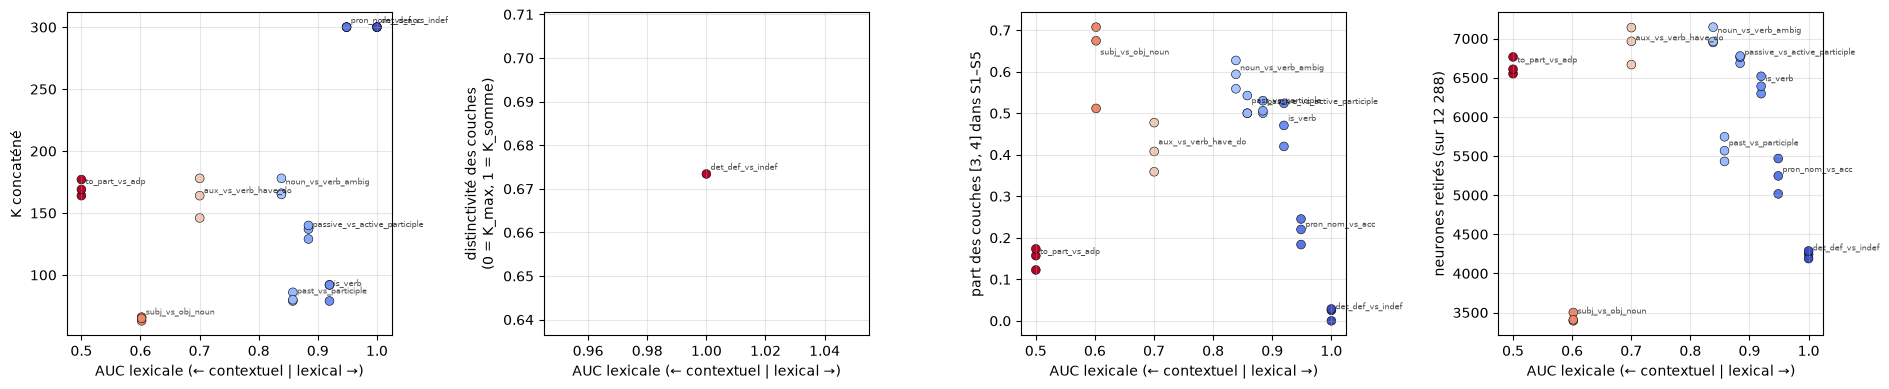

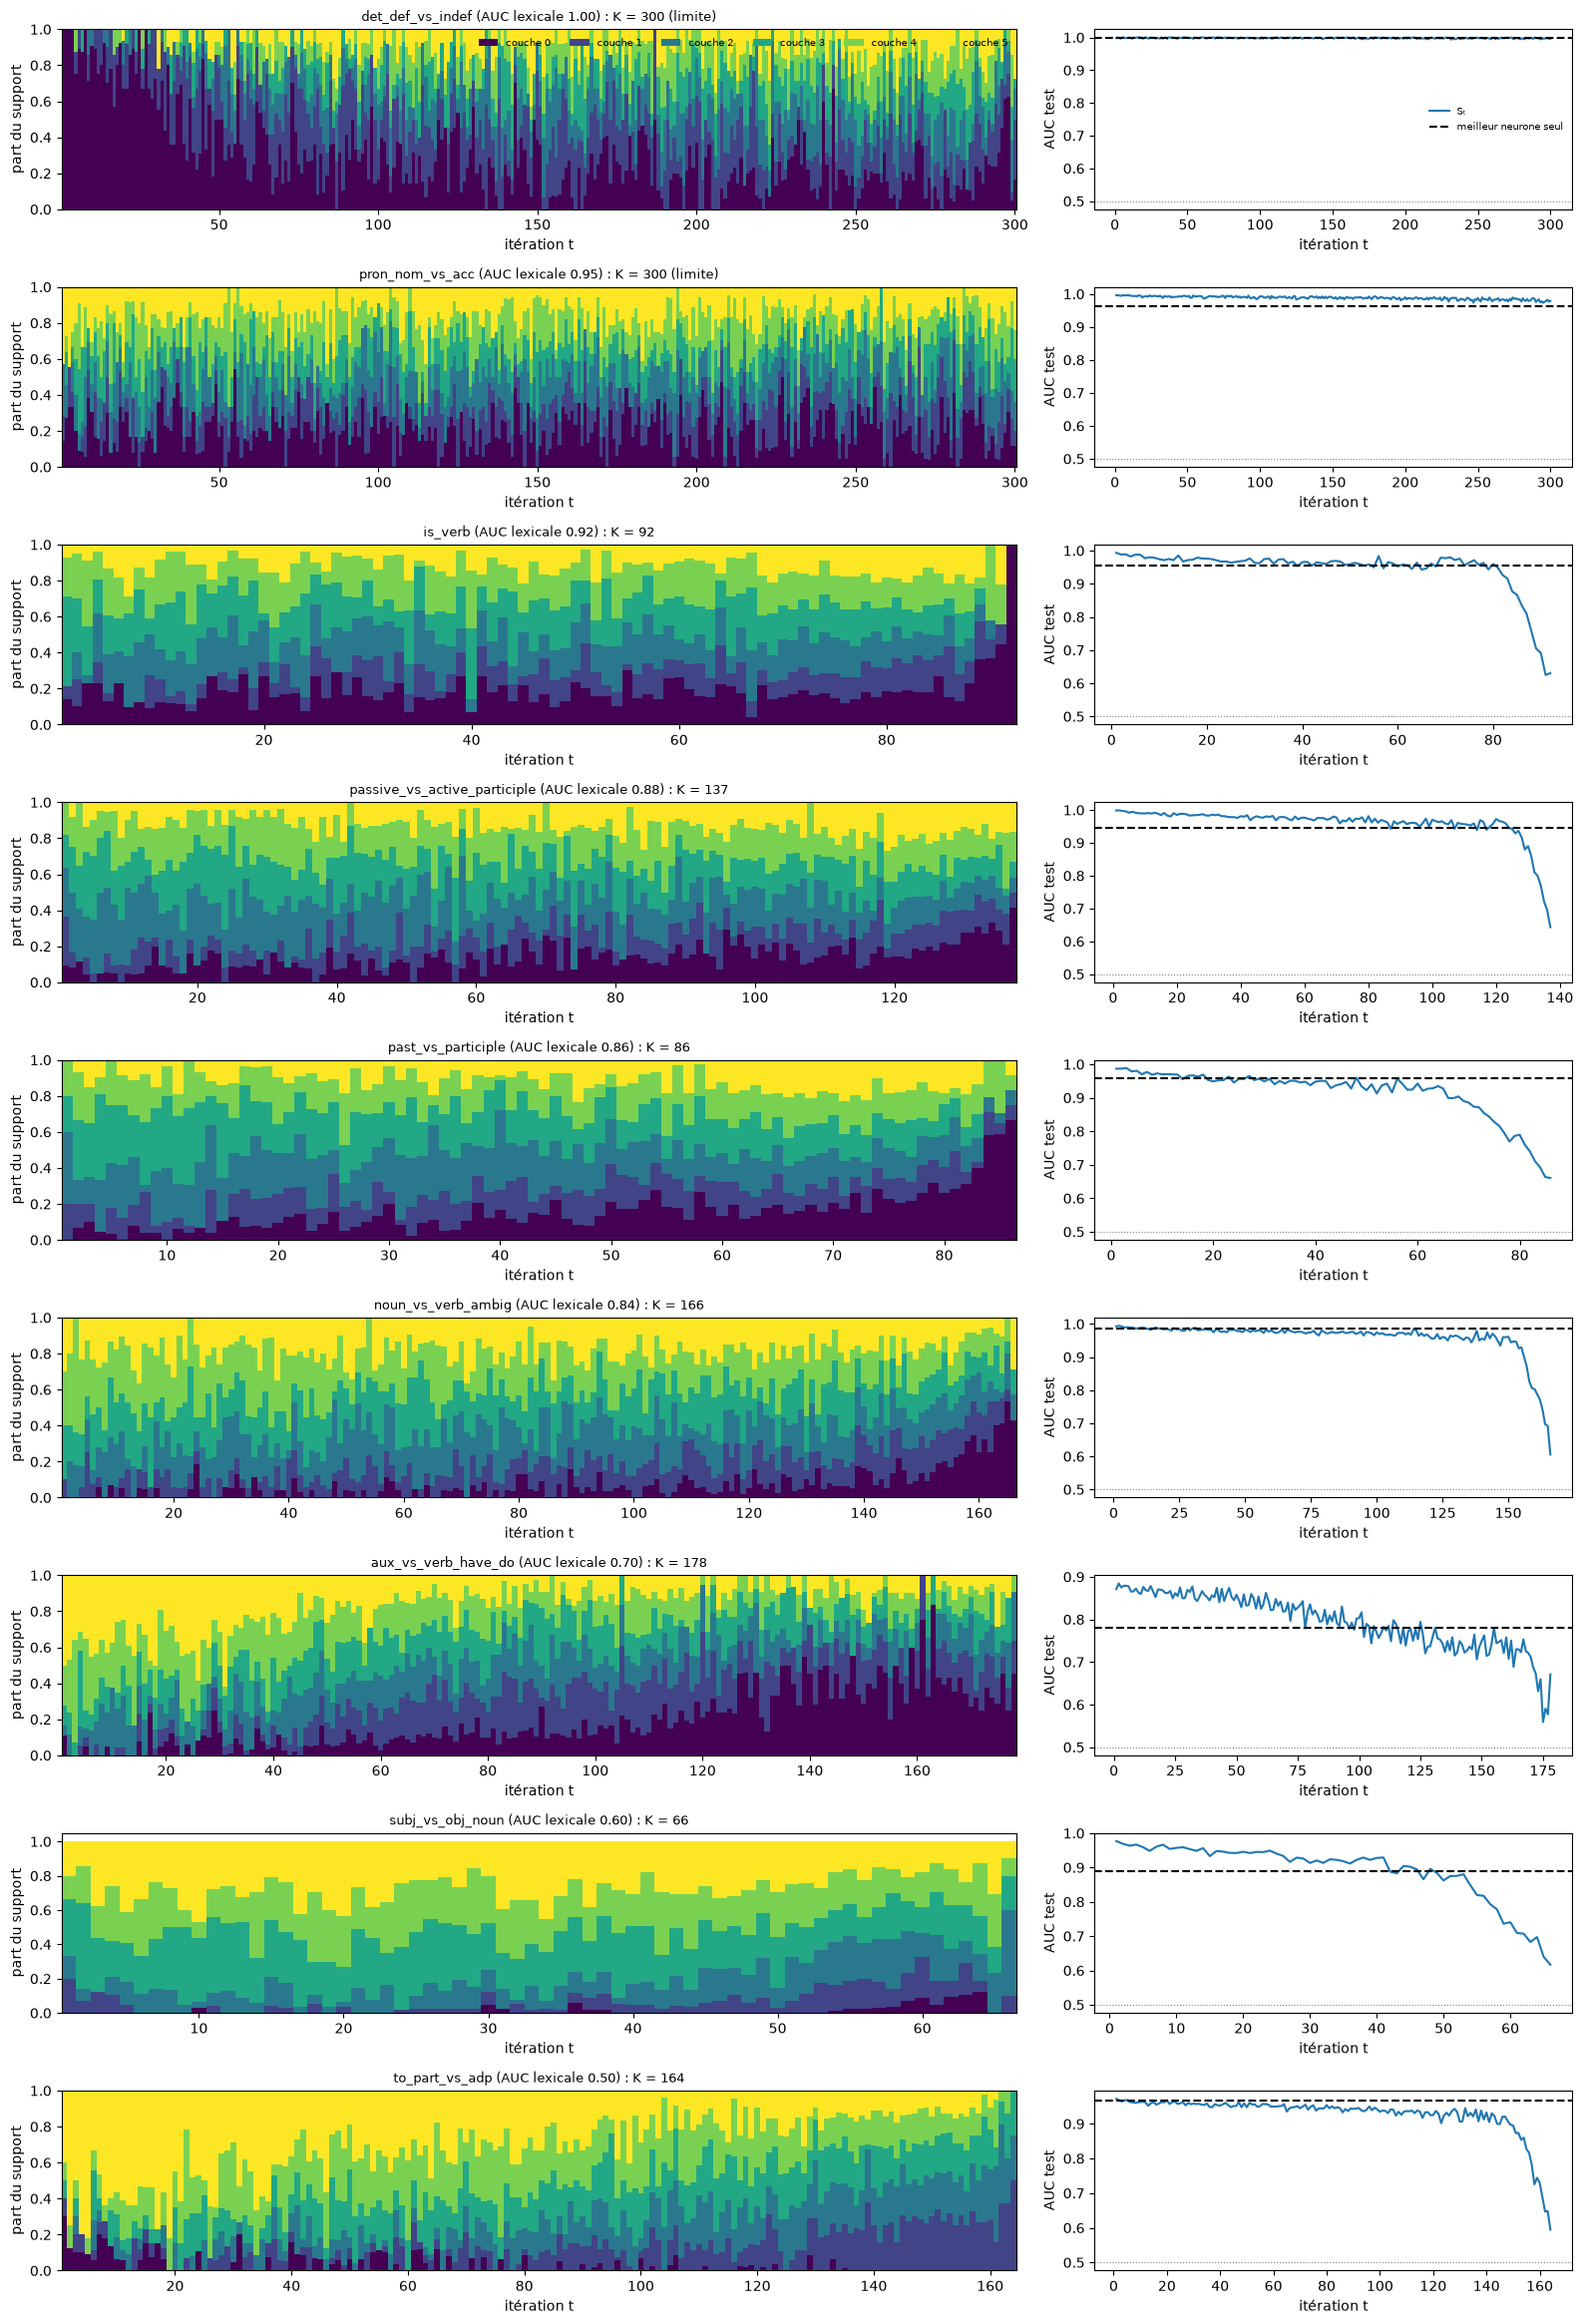

In [34]:
RCAT = {}
for f in sorted(os.listdir(OUT_CAT)):
    if f.endswith(".pkl"):
        with open(f"{OUT_CAT}/{f}", "rb") as fh:
            RCAT[f[:-4]] = pickle.load(fh)

MID = [3, 4]                    # couches du milieu
EARLY_T = 5                     # premiers supports : S1 à S5


def layer_share(r, layers, t_max=None):
    """Part des neurones des supports S1..S_t_max qui viennent des couches `layers`."""
    lc = r["layer_counts"][:t_max]
    tot = sum(sum(c.values()) for c in lc)
    return sum(c[l] for c in lc for l in layers) / tot if tot else np.nan


# ---- tableau : une ligne par run ----
rows = []
for k, r in RCAT.items():
    row = dict(run=k, task=r["task"], seed=r["seed"], nul=r["shuffled"],
               K_concat=r["K"], arret_naturel=r["stopped"], neurones_retires=int(sum(r["sizes"])),
               AUC_S1=r["levels"][0]["auc"] if r["levels"] else np.nan,
               AUC_meilleur_neurone=r["baseline"]["auc"],
               meilleur_neurone=f"L{r['baseline_best_layer']}.N{r['baseline_best_neuron']}",
               part_milieu_S1_5=layer_share(r, MID, EARLY_T), part_L0_total=layer_share(r, [0]))
    if not r["shuffled"]:
        Ks = []
        for l in CAT_LAYERS:
            p = result_path(r["task"], l, r["seed"])
            if os.path.exists(p):
                with open(p, "rb") as fh:
                    Ks.append(len(pickle.load(fh)["supports"]))
                row[f"K_L{l}"] = Ks[-1]
        if len(Ks) == len(CAT_LAYERS):
            row["K_somme"], row["K_max"] = sum(Ks), max(Ks)
            # 0 = K_concat au niveau du max (couches redondantes), 1 = au niveau de la somme (couches distinctes)
            row["distinctivite"] = (r["K"] - max(Ks)) / max(sum(Ks) - max(Ks), 1)
    rows.append(row)
CAT = pd.DataFrame(rows)
CAT["AUC_lexicale"] = CAT.task.map(CTX["AUC_lexicale"])
CAT = CAT.sort_values(["nul", "AUC_lexicale"], ascending=[True, False])
CAT.to_csv(f"{OUT_CAT}/resume.csv", index=False)
display(CAT.set_index("run").drop(columns=["task", "seed"]).round(3))

null = CAT[CAT.nul]
if len(null):
    print("Contrôle nul :", ", ".join(f"{r.run} -> K = {r.K_concat}" for r in null.itertuples()),
          "(attendu : 0)")

# ---- figure 1 : synthèse en fonction de la contextualité ----
C = CAT[~CAT.nul].dropna(subset=["AUC_lexicale"])
if len(C):
    fig, axes = plt.subplots(1, 4, figsize=(19, 4))
    for ax, col, lab in zip(axes,
                            ["K_concat", "distinctivite", "part_milieu_S1_5", "neurones_retires"],
                            ["K concaténé", "distinctivité des couches\n(0 = K_max, 1 = K_somme)",
                             f"part des couches {MID} dans S1–S{EARLY_T}", "neurones retirés (sur 12 288)"]):
        if col not in C:
            ax.set_visible(False)
            continue
        ax.scatter(C.AUC_lexicale, C[col], c=C.AUC_lexicale, cmap="coolwarm_r", s=40, edgecolor="k", lw=0.4)
        for t, d in C.groupby("task"):
            ax.annotate(t, (d.AUC_lexicale.iloc[0], d[col].mean()), fontsize=6, alpha=0.7,
                        xytext=(3, 3), textcoords="offset points")
        ax.set_xlabel("AUC lexicale (← contextuel | lexical →)")
        ax.set_ylabel(lab); ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# ---- figure 2 : composition par couche de chaque Sₜ et AUC, tirage 0, tâches triées ----
runs = [r.run for r in CAT[~CAT.nul & (CAT.seed == SEEDS_CAT[0]) & (CAT.K_concat > 0)].itertuples()]
if runs:
    pal = plt.get_cmap("viridis", len(CAT_LAYERS))
    fig, axes = plt.subplots(len(runs), 2, figsize=(16, 2.6 * len(runs)), squeeze=False,
                             gridspec_kw={"width_ratios": [2, 1]})
    for i, k in enumerate(runs):
        r = RCAT[k]
        t = np.arange(1, r["K"] + 1)
        share = np.array([[c[l] / max(sum(c.values()), 1) for l in CAT_LAYERS] for c in r["layer_counts"]])
        bottom = np.zeros(len(t))
        for j, l in enumerate(CAT_LAYERS):
            axes[i, 0].bar(t, share[:, j], bottom=bottom, color=pal(j), width=1.0, label=f"couche {l}")
            bottom += share[:, j]
        axes[i, 0].set_ylabel("part du support")
        axes[i, 0].set_title(f"{r['task']} (AUC lexicale {CTX.loc[r['task'], 'AUC_lexicale']:.2f}) : "
                             f"K = {r['K']}{'' if r['stopped'] else ' (limite)'}", fontsize=9)
        axes[i, 0].set_xlim(0.5, len(t) + 0.5)
        axes[i, 1].plot(t, [v["auc"] for v in r["levels"]], color="tab:blue", label="Sₜ")
        axes[i, 1].axhline(r["baseline"]["auc"], color="black", ls="--", label="meilleur neurone seul")
        axes[i, 1].axhline(0.5, color="gray", ls=":", lw=0.8)
        axes[i, 1].set_ylabel("AUC test")
        for a in axes[i]:
            a.set_xlabel("itération t")
    axes[0, 0].legend(frameon=False, fontsize=7, ncol=len(CAT_LAYERS), loc="upper right")
    axes[0, 1].legend(frameon=False, fontsize=7)
    plt.tight_layout()
    plt.show()

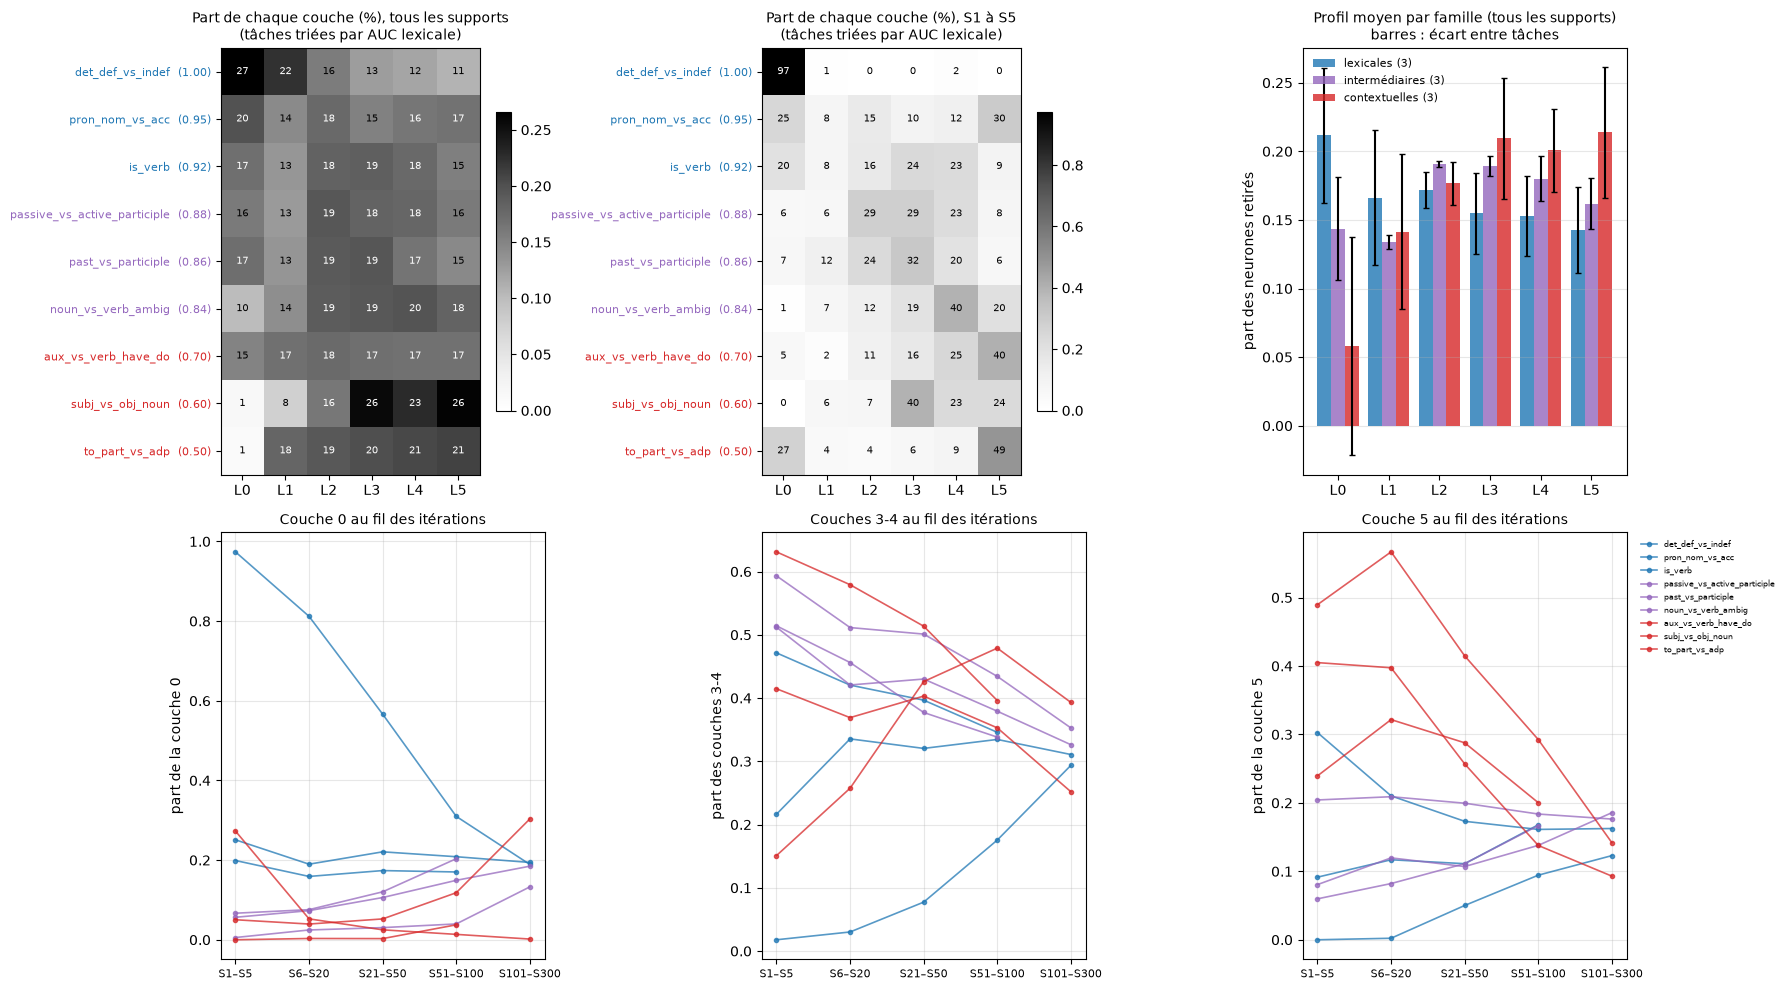

,0,1,2,3,4,5,famille,AUC_lexicale
det_def_vs_indef,26.6,22.2,15.7,12.7,12.0,10.8,lexicales,1.00
pron_nom_vs_acc,19.9,14.4,17.6,15.2,16.3,16.6,lexicales,0.95
is_verb,17.0,13.2,18.2,18.5,17.6,15.4,lexicales,0.92
passive_vs_active_participle,15.9,12.9,19.3,18.1,17.8,15.9,intermédiaires,0.88
past_vs_participle,17.1,13.4,19.0,19.5,16.5,14.5,intermédiaires,0.86
noun_vs_verb_ambig,10.1,14.0,18.9,19.2,19.7,18.1,intermédiaires,0.84
aux_vs_verb_have_do,15.0,16.8,17.6,17.0,16.8,16.8,contextuelles,0.70
subj_vs_obj_noun,1.4,7.6,16.1,25.7,22.8,26.3,contextuelles,0.60
to_part_vs_adp,1.0,17.9,19.3,20.1,20.6,21.1,contextuelles,0.50


In [35]:
FAMILIES = {
    "lexicales": ["det_def_vs_indef", "pron_nom_vs_acc", "is_verb"],
    "intermédiaires": ["passive_vs_active_participle", "past_vs_participle", "noun_vs_verb_ambig"],
    "contextuelles": ["aux_vs_verb_have_do", "subj_vs_obj_noun", "to_part_vs_adp"],
}
FAM_OF = {t: f for f, ts in FAMILIES.items() for t in ts}
FAM_COLOR = {"lexicales": "tab:blue", "intermédiaires": "tab:purple", "contextuelles": "tab:red"}
T_BINS = [(1, 5), (6, 20), (21, 50), (51, 100), (101, 300)]    # tranches d'itérations


def shares(r, t_min=1, t_max=None):
    """Part de chaque couche parmi les neurones des supports S_t_min..S_t_max."""
    lc = r["layer_counts"][t_min - 1:t_max]
    tot = np.array([sum(c[l] for c in lc) for l in CAT_LAYERS], float)
    return tot / tot.sum() if tot.sum() else np.full(len(CAT_LAYERS), np.nan)


runs = {k: r for k, r in RCAT.items() if not r["shuffled"] and r["K"] > 0 and r["task"] in FAM_OF}
order = [t for t in CTX.index if t in {r["task"] for r in runs.values()}]   # du plus lexical au plus contextuel


def task_mean(task, **kw):
    v = [shares(r, **kw) for r in runs.values() if r["task"] == task]
    return np.nanmean(v, axis=0)


tot_all = pd.DataFrame({t: task_mean(t) for t in order}, index=CAT_LAYERS).T
tot_early = pd.DataFrame({t: task_mean(t, t_max=5) for t in order}, index=CAT_LAYERS).T

fig = plt.figure(figsize=(18, 10))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1])

# ---- 1. heatmaps : tâches x couches, tous les supports puis S1-S5 ----
for col, (tab, title) in enumerate([(tot_all, "tous les supports"), (tot_early, "S1 à S5")]):
    ax = fig.add_subplot(gs[0, col])
    im = ax.imshow(tab.values, cmap="Greys", vmin=0, vmax=np.nanmax(tab.values), aspect="auto")
    ax.set_xticks(range(len(CAT_LAYERS))); ax.set_xticklabels([f"L{l}" for l in CAT_LAYERS])
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels([f"{t}  ({CTX.loc[t, 'AUC_lexicale']:.2f})" for t in order], fontsize=8)
    for lab, t in zip(ax.get_yticklabels(), order):
        lab.set_color(FAM_COLOR[FAM_OF[t]])
    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            v = tab.values[i, j]
            ax.text(j, i, f"{100 * v:.0f}", ha="center", va="center", fontsize=7,
                    color="white" if v > 0.6 * np.nanmax(tab.values) else "black")
    ax.set_title(f"Part de chaque couche (%), {title}\n(tâches triées par AUC lexicale)", fontsize=10)
    fig.colorbar(im, ax=ax, shrink=0.7)

# ---- 2. profil moyen par famille ----
ax = fig.add_subplot(gs[0, 2])
w = 0.27
for i, (fam, ts) in enumerate(FAMILIES.items()):
    ts = [t for t in ts if t in tot_all.index]
    if not ts:
        continue
    m, s = tot_all.loc[ts].mean(), tot_all.loc[ts].std()
    ax.bar(np.arange(len(CAT_LAYERS)) + (i - 1) * w, m, w, yerr=s, color=FAM_COLOR[fam],
           alpha=0.8, capsize=2, label=f"{fam} ({len(ts)})")
ax.set_xticks(range(len(CAT_LAYERS))); ax.set_xticklabels([f"L{l}" for l in CAT_LAYERS])
ax.set_ylabel("part des neurones retirés"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Profil moyen par famille (tous les supports)\nbarres : écart entre tâches", fontsize=10)
ax.grid(alpha=0.3, axis="y")

# ---- 3. évolution avec t : couche 0, couches 3-4, couche 5 ----
for col, (layers, lab) in enumerate([([0], "couche 0"), ([3, 4], "couches 3-4"), ([5], "couche 5")]):
    ax = fig.add_subplot(gs[1, col])
    jl = [CAT_LAYERS.index(l) for l in layers]
    x = np.arange(len(T_BINS))
    for t in order:
        v = []
        for a, b in T_BINS:
            sh = [shares(r, a, b) for r in runs.values() if r["task"] == t and r["K"] >= a]
            v.append(np.nanmean([s[jl].sum() for s in sh]) if sh else np.nan)
        ax.plot(x, v, "-o", ms=3, lw=1.2, color=FAM_COLOR[FAM_OF[t]], alpha=0.75, label=t)
    ax.set_xticks(x); ax.set_xticklabels([f"S{a}–S{b}" for a, b in T_BINS], fontsize=8)
    ax.set_ylabel(f"part de la {lab}" if len(layers) == 1 else f"part des {lab}")
    ax.set_title(f"{lab.capitalize()} au fil des itérations", fontsize=10)
    ax.grid(alpha=0.3)
fig.axes[-1].legend(frameon=False, fontsize=6, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

display((100 * tot_all).round(1).assign(famille=[FAM_OF[t] for t in tot_all.index],
                                        AUC_lexicale=CTX.loc[tot_all.index, "AUC_lexicale"].round(2)))